# 02 - Feature Engineering

How the customer-level feature table is built, why each feature matters, and a live demonstration that the features contain **no information from after the cutoff date** (no target leakage).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.features.analysis import target_correlations, vif_table
from src.features.build_features import TARGET_COLUMNS, feature_columns
from src.utils.config import load_config, resolve_path

cfg = load_config()
CATEGORIES = cfg["features"]["categories"]
FEATURES = feature_columns(CATEGORIES)
sns.set_theme(style="whitegrid")

from src.features.build_features import build_customer_features
from src.data.clean import select_customer_lines

## 1. Feature dictionary

| Feature | How it is computed (only data before the cutoff) | Why it matters |
|---|---|---|
| `recency_days` | Days from the last purchase to the cutoff | Directly precedes churn; usually the strongest churn signal |
| `frequency` | Number of distinct purchase invoices | Separates habitual buyers from one-time buyers |
| `monetary_total`, `monetary_avg` | Total spend and spend per order | Core input for churn weighting and CLV |
| `clv_historical` | Total sales minus the value of returns | Prioritizes retention spend by return, not only by risk |
| `avg_basket_qty`, `avg_basket_lines` | Mean items and mean distinct products per order | Top-up shopper versus bulk shopper |
| `frequency_trend` | Slope of monthly order counts up to the cutoff | Shows acceleration or deceleration that an average hides |
| `gap_variance` | Variance of days between consecutive orders | High variance means irregular, harder-to-predict customers |
| `seasonal_concentration` | Herfindahl index of spend over calendar months (1/12 = flat, 1 = one month) | Separates gift or seasonal shoppers from year-round customers |
| `cat_share_*` | Share of spend per keyword-based product category | Feeds recommendations and next-category prediction |
| `return_rate` | Returned quantity divided by sold quantity (0 to 1) | Leading indicator of dissatisfaction |
| `discount_sensitivity` | Share of units bought below 90% of the product's median price | Proxy for who responds to promotions (the data has no discount field) |
| `engagement_score` | Mean percentile rank of recency (inverted), frequency and monetary, scaled 0-100 | One interpretable score for the dashboard |

**Targets:** `churn_90d` = 1 if the customer made no purchase in the 90 days after the cutoff; `clv_target` = sales revenue in those 90 days.

In [2]:
tx = pd.read_csv(resolve_path(cfg["paths"]["interim_transactions"]), parse_dates=["invoice_date"], low_memory=False)
lines = select_customer_lines(tx)
fcfg = cfg["features"]
table = build_customer_features(lines, fcfg["cutoff_date"], fcfg["horizon_days"], CATEGORIES, fcfg["discount_threshold"])
print("cutoff:", fcfg["cutoff_date"], "| horizon:", fcfg["horizon_days"], "days")
print("customers:", len(table), "| churn rate:", round(table["churn_90d"].mean(), 3))
table.head()

cutoff: 2011-09-10 | horizon: 90 days
customers: 5256 | churn rate: 0.565


,customer_id,country,recency_days,frequency,monetary_total,monetary_avg,clv_historical,avg_basket_qty,avg_basket_lines,frequency_trend,...,cat_share_lighting_candles,cat_share_bags_storage,cat_share_kitchen_dining,cat_share_home_decor,cat_share_stationery_cards,cat_share_toys_games,cat_share_garden_outdoor,cat_share_jewellery_accessories,churn_90d,clv_target
0,12346,United Kingdom,438,2,169.36,84.680,169.36,12.000000,12.000000,-0.026316,...,0.000000,0.000000,0.044225,0.707605,0.000000,0.000000,0.000000,0.0,1,0.00
1,12347,Iceland,38,6,3402.39,567.065,3402.39,349.833333,27.333333,-0.027972,...,0.092864,0.235055,0.087497,0.146562,0.114978,0.000000,0.013314,0.0,0,1519.14
2,12348,Finland,157,4,1388.40,347.100,1388.40,622.000000,10.000000,-0.054945,...,0.000000,0.242005,0.000000,0.127139,0.223423,0.012244,0.000000,0.0,0,270.00
3,12349,Italy,316,2,2221.14,1110.570,2196.99,495.500000,50.000000,-0.022704,...,0.011481,0.151904,0.164425,0.270438,0.065777,0.000000,0.033920,0.0,0,1457.55
4,12350,Norway,219,1,294.40,294.400,294.40,196.000000,16.000000,-0.083333,...,0.000000,0.254755,0.000000,0.230299,0.000000,0.000000,0.000000,0.0,1,0.00


## 2. Leakage check

If the pipeline respects the cutoff, deleting every transaction after the cutoff must leave all features unchanged.

In [3]:
cutoff = pd.Timestamp(fcfg["cutoff_date"])
history_only = build_customer_features(lines[lines["invoice_date"] < cutoff], cutoff, fcfg["horizon_days"], CATEGORIES, fcfg["discount_threshold"])
cols = ["customer_id", *FEATURES]
same = table[cols].set_index("customer_id").sort_index().equals(history_only[cols].set_index("customer_id").sort_index())
print("Features identical with and without post-cutoff data:", same)

Features identical with and without post-cutoff data: True


## 3. Class balance and target distribution

churn_90d
1    0.565
0    0.435
Name: proportion, dtype: float64


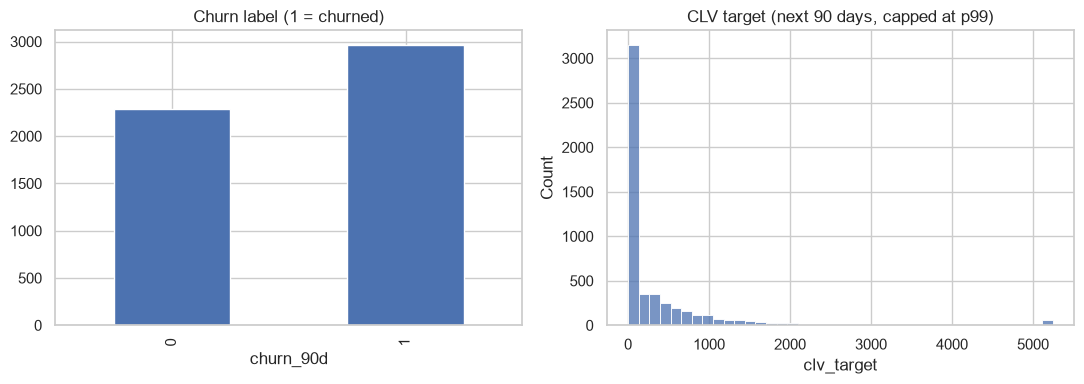

In [4]:
print(table["churn_90d"].value_counts(normalize=True).round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
table["churn_90d"].value_counts().sort_index().plot.bar(ax=axes[0], title="Churn label (1 = churned)")
sns.histplot(table["clv_target"].clip(upper=table["clv_target"].quantile(0.99)), bins=40, ax=axes[1]).set_title("CLV target (next 90 days, capped at p99)")
plt.tight_layout()
plt.show()

## 4. Final checks before modeling

In [5]:
print("Missing values in features:", int(table[FEATURES].isna().sum().sum()))
print("Duplicate customers:", int(table["customer_id"].duplicated().sum()))
print("Negative recency:", int((table["recency_days"] < 0).sum()))
vif_table(table, [c for c in FEATURES if table[c].nunique() > 1]).round(2).head(8)

Missing values in features: 0
Duplicate customers: 0
Negative recency: 0


,feature,vif
0,monetary_total,620.35
1,clv_historical,604.56
2,engagement_score,12.22
3,seasonal_concentration,6.02
4,recency_days,3.79
5,frequency,2.53
6,monetary_avg,2.19
7,cat_share_bags_storage,1.58
